# RCBNB-MB: 원자재별 레짐과 레짐별 인과 그래프

방법: Zan et al., *Beyond Stationarity in Time Series* (arXiv 2609.05150). 두 단계를 번갈아 반복한다.
1. 레짐별로 CBNB 인과 그래프를 추정한다 (PCMCI+ 로 뼈대·시차 방향, LiNGAM 으로 동시점 방향).
2. 각 주를 "그 주의 모든 변수를 Markov blanket 으로 가장 잘 예측하는 레짐"에 다시 배정한다.

- 데이터: `weekly_prices.parquet`(로그 수익률) + `exogenous_nodelay.parquet` 의 drivers 전부, 2015-01-04 이후.
- 고정: τ_max = 4, 유의수준 0.05.
- 레짐 수 r · 최소 레짐 크기 N_ℓ · 최대 전환 횟수 N_c 는 경제 지식으로 후보를 정하고 세 가지 방식(A 보류 표본 검정, B BIC, C 경제 지식 고정)으로 고른다.
- 채점: `docs/commodity_weekly_drivers.xlsx` 의 주별 원인표(2023-01 ~ 2026-10).

이미 본 기간을 탐색하는 분석이다. 예측 성능 평가가 아니다.

In [1]:
import hashlib, os, pickle, warnings

import lingam
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import sparse, stats
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.signal import find_peaks
from scipy.sparse.csgraph import connected_components
from tigramite import data_processing as pp
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.pcmci import PCMCI

from causal_common import ALPHA, MISSING, SERIES, START, TAU, ROOT, load_key, make_panel, prices  # 데이터·변환·답지: analysis/causal_common.py

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"  # 병렬 작업 프로세스에도 적용
CACHE = ROOT / "data/07_reporting/rcbnb_mb"  # 적합 결과 캐시. 알고리즘 셀을 바꾸면 이 폴더를 지운다.
CACHE.mkdir(parents=True, exist_ok=True)

SEASON = 52          # 최소 레짐 크기 하한: 작황·계절 한 바퀴
R_MAX = 4            # 레짐 수 상한
BULL_BEAR = 0.20     # 강세·약세 전환 기준: 20% 등락
MIN_VALID = 52       # 레짐 안 유효 주가 이보다 적은 변수는 그 레짐 그래프에서 뺀다
HOLDOUT = 0.2        # 방식 A 에서 빼 두는 주의 비율
N_INIT, N_ITER = 20, 20  # 무작위 초기화 수, 초기화당 최대 반복
MILP_SECONDS = 10    # 배정 문제 한 번의 시간 제한

## 1. 변수 변환 — 계단형(월·분기) 변수의 정보 살리기

주간 차분을 하면 월·분기 변수는 80~95% 가 0 이 되고, τ = 4 로는 값이 바뀐 주 뒤 5주만 보게 된다.

| 변수 | 변환 |
| --- | --- |
| 주간 변수 | 1주 변화 (양수이고 금리·비율이 아니면 로그 차분) |
| 계단형, 발표값 열이 정상 (ADF p < 0.05) | 수준 그대로 |
| 계단형, 비정상 | 직전 발표값 대비 변화를 다음 발표까지 유지 |

발표 한 주기 전체가 lag 0 링크 하나에 모이고, 미래 값은 쓰지 않는다. 정보량의 상한은 발표 횟수다.
늦게 시작하는 변수는 빼지 않고 결측으로 둔다. 마지막에 모든 열을 z-score 로 맞춘다(식 (6) 이 변수별 제곱오차를 더한다).
변환 코드는 `analysis/causal_common.py` 의 `make_panel` — PCMCI-LPCMCI 노트북과 같은 함수를 쓴다.

In [2]:
panels = {s: make_panel(s) for s in SERIES}
for s, (X, info) in panels.items():
    print(f"\n== {s}: T={len(X)}, d={X.shape[1]}, 결측 비율={X.isna().mean().mean():.3f}")
    print(info.assign(변수=info.변수.str[:58]).to_string(index=False))


== coffee: T=619, d=21, 결측 비율=0.086
                                                        변수                  code            변환 로그  변화 횟수  주간 변화 비율         시작
                     Climate_USDM_CONUS_D0_D4_Area_Percent      EXT.CLIM.DROUGHT         주간 변화       614      0.99 2000-01-09
                                        Com_CBOE_VIX_Index    PFM.AST.VOLATILITY         주간 변화 로그    618      1.00 1990-01-07
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE      PFM.POS.INVESTOR         주간 변화 로그    615      0.99 1990-01-07
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE      PFM.POS.INVESTOR         주간 변화 로그    615      0.99 1990-01-07
Com_Cecafe_Brazil_Arabica_Coffee_Exports_Million_60kg_Bags        FND.TRD.EXPORT 계단형: 발표 변화 유지 로그    128      0.23 2016-01-31
Com_Cecafe_Brazil_Conillon_Coffee_Exports_Million_60kg_Bag        FND.TRD.EXPORT 계단형: 발표 변화 유지 로그    128      0.23 2016-01-31
Com_Conab_Brazil_Coffee_Arabica_Production_Estimate_Millio    FND.SUP.PRODUCTION 

## 2. 알고리즘 (논문 Algorithm 1)

- `cbnb`: 레짐 안의 주만으로 window 그래프를 만든다. `A[i, j, τ]` 는 X^i(t−τ) → X^j(t).
- `markov_blankets`: 변수별 부모·자식·배우자를 (변수, 시차 −τ..+τ) 로.
- `sq_errors`: (레짐, 변수)마다 Markov blanket 선형 회귀 → 모든 주의 제곱오차.
- `assign`: 식 (7) 최소화. 제약은 주마다 레짐 하나, 레짐당 N_ℓ 주 이상, 레짐당 전환 N_c 이하.
- `run_init` / `fit`: 무작위 초기화 → 반복 → 손실이 가장 작은 초기화를 고른다.

In [3]:
def lagged(X):
    """Z[t, i, TAU + o] = X[t + o, i], o = -TAU..TAU (범위 밖은 NaN)."""
    T, d = X.shape
    Z = np.full((T, d, 2 * TAU + 1), np.nan)
    for o in range(-TAU, TAU + 1):
        lo, hi = max(0, -o), min(T, T - o)
        Z[lo:hi, :, TAU + o] = X[lo + o:hi + o]
    return Z


def ols_predict(P, y, fit, ok):
    """fit 행으로 적합하고 ok 행을 예측한다 (절편 포함)."""
    D = np.column_stack([np.ones(len(P)), P])
    return D[ok] @ np.linalg.lstsq(D[fit], y[fit], rcond=None)[0]


def cbnb(X, Z, sel):
    T, d = X.shape
    act = np.flatnonzero((~np.isnan(X[sel])).sum(0) >= MIN_VALID)
    ix = np.ix_(act, act)
    frame = pp.DataFrame(np.nan_to_num(X[:, act], nan=MISSING), missing_flag=MISSING,
                         mask=np.repeat(~sel[:, None], len(act), 1))
    out = PCMCI(frame, ParCorr(significance="analytic", mask_type="y"), verbosity=0).run_pcmciplus(
        tau_min=0, tau_max=TAU, pc_alpha=ALPHA)
    A, val, S = np.zeros((d, d, TAU + 1), bool), np.full((d, d, TAU + 1), np.nan), np.zeros((d, d), bool)
    A[ix], val[ix], S[ix] = out["graph"] == "-->", out["val_matrix"], out["graph"][:, :, 0] != ""
    A[:, :, 0] = False  # 동시점 방향은 아래 noise-based 단계가 정한다
    n_comp, comp = connected_components(sparse.csr_matrix(S), directed=False)
    for c in range(n_comp):
        m = np.flatnonzero(comp == c)
        if len(m) < 2:
            continue
        par = sorted({(int(i), int(t)) for j in m for i, t in zip(*np.nonzero(A[:, j]))})  # 시차 부모를 공변량으로
        P = np.column_stack([Z[:, i, TAU - t] for i, t in par]) if par else np.empty((T, 0))
        ok = sel & ~np.isnan(P).any(1) & ~np.isnan(X[:, m]).any(1)
        E = np.column_stack([X[ok, j] - ols_predict(P, X[:, j], ok, ok) for j in m])
        rank = np.argsort(lingam.DirectLiNGAM().fit(E).causal_order_)  # rank[a] 가 작을수록 원인 쪽
        for a in range(len(m)):
            for b in range(len(m)):
                if S[m[a], m[b]] and rank[a] < rank[b]:
                    A[m[a], m[b], 0] = True
    return A, val


def markov_blankets(A):
    out = []
    for j in range(A.shape[0]):
        mb = {(int(i), -int(t)) for i, t in zip(*np.nonzero(A[:, j]))}
        for c, t in zip(*np.nonzero(A[j])):
            mb.add((int(c), int(t)))
            mb |= {(int(m), int(t - t2)) for m, t2 in zip(*np.nonzero(A[:, c]))}
        out.append(sorted(mb - {(j, 0)}))
    return out


def sq_errors(X, Z, mbs, train):
    r, (T, d) = len(mbs), X.shape
    E = np.full((r, T, d), np.nan)
    for k in range(r):
        for j in range(d):
            P = np.column_stack([Z[:, i, TAU + o] for i, o in mbs[k][j]]) if mbs[k][j] else np.empty((T, 0))
            ok = ~np.isnan(X[:, j]) & ~np.isnan(P).any(1)
            fit = ok & train[k]
            if fit.sum() > P.shape[1] + 1:
                E[k, ok, j] = (X[ok, j] - ols_predict(P, X[:, j], fit, ok)) ** 2
    E[:, np.isnan(E).any(0)] = 0  # 어느 레짐에서든 예측할 수 없는 항은 배정에 표를 던지지 않는다
    return E


def assign(cost, n_min, n_switch):
    r, T = cost.shape
    n, m = r * T, r * (T - 1)
    D = sparse.kron(sparse.eye(r), sparse.diags([-1.0, 1.0], [0, 1], shape=(T - 1, T)))
    rows = sparse.bmat([
        [sparse.kron(np.ones((1, r)), sparse.eye(T)), None],  # 주마다 레짐 하나
        [D, -sparse.eye(m)], [-D, -sparse.eye(m)],            # eta >= |gamma(t+1) - gamma(t)|
        [None, sparse.kron(sparse.eye(r), np.ones((1, T - 1)))],  # 레짐당 전환 <= N_c
        [sparse.kron(sparse.eye(r), np.ones((1, T))), None],      # 레짐당 주 수 >= N_l
    ], format="csr")
    lo = np.r_[np.ones(T), np.full(2 * m, -np.inf), np.zeros(r), np.full(r, n_min)]
    hi = np.r_[np.ones(T), np.zeros(2 * m), np.full(r, n_switch), np.full(r, T)]
    res = milp(np.r_[cost.ravel(), np.zeros(m)], constraints=LinearConstraint(rows, lo, hi),
               integrality=np.r_[np.ones(n), np.zeros(m)], bounds=Bounds(0, 1),
               options={"time_limit": MILP_SECONDS})
    if res.x is None:
        raise ValueError("배정 문제에 해가 없다")
    return res.x[:n].reshape(r, T).argmax(0)


def run_init(X, r, n_min, n_switch, seed, hold):
    T, d = X.shape
    rng, Z = np.random.default_rng(seed), lagged(X)
    slack = T - r * n_min  # 무작위 연속 구간, 구간마다 n_min 주 이상
    sizes = np.diff(np.r_[0, np.sort(rng.integers(0, slack + 1, r - 1)), slack]) + n_min
    labels = np.repeat(rng.permutation(r), sizes)
    try:
        for it in range(N_ITER):
            train = [(labels == k) & ~hold for k in range(r)]
            graphs = [cbnb(X, Z, sel) for sel in train]
            mbs = [markov_blankets(A) for A, _ in graphs]
            E = sq_errors(X, Z, mbs, train)
            cost = E.sum(-1)
            new = assign(np.where(hold, 0, cost), n_min, n_switch) if r > 1 else labels
            done, labels = bool((new == labels).all()), new
            if done:
                break
    except Exception as err:  # 표본 부족·특이 행렬 등: 이 초기화는 버린다
        return None
    order = pd.unique(labels)  # 레짐 번호 = 처음 등장한 순서
    week_loss = cost[labels, np.arange(T)]
    return dict(labels=np.argsort(order)[labels], graphs=[graphs[k] for k in order], mbs=[mbs[k] for k in order],
                week_loss=week_loss, loss=float(week_loss[~hold].sum()), converged=done, iters=it + 1,
                n_terms=int((E[0][~hold] > 0).sum()), n_coef=sum(len(b) + 1 for mb in mbs for b in mb))


def fit(X, r, n_min, n_switch, hold=None):
    hold = np.zeros(len(X), bool) if hold is None else hold
    key = hashlib.md5(X.tobytes() + hold.tobytes() + repr((r, n_min, n_switch, TAU, ALPHA, N_INIT, N_ITER)).encode())
    path = CACHE / f"{key.hexdigest()}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    runs = Parallel(n_jobs=-1)(delayed(run_init)(X, r, n_min, n_switch, s, hold) for s in range(N_INIT if r > 1 else 1))
    runs = [x for x in runs if x is not None]
    best = min(runs, key=lambda x: x["loss"]) if runs else None
    if best:
        best["n_ok"] = len(runs)
    path.write_bytes(pickle.dumps(best))
    return best

### 자체 점검 — 논문 5.1 의 합성 데이터

변수 6개, 길이 600, 앞 절반과 뒤 절반의 그래프가 다른 선형 모형. 레짐을 잘못 배정한 주의 비율(MER)이 10% 미만이어야 한다.

In [4]:
def simulate(seed, d=6, T=600, r=2):
    rng = np.random.default_rng(seed)
    while True:
        Bs = []
        for _ in range(r):
            B, order = np.zeros((2, d, d)), rng.permutation(d)  # B[tau, i, j]: X^i(t-tau) -> X^j(t)
            coef = lambda: rng.uniform(0.5, 0.9) * rng.choice([-1, 1])
            for i in range(d):
                B[1, i, i] = coef()
                for j in range(d):
                    if i != j and rng.random() < 0.3:
                        lag = int(rng.integers(0, 2))
                        if lag == 1 or order[i] < order[j]:
                            B[lag, i, j] = coef()
            Bs.append((B, np.argsort(order)))
        X, truth = np.zeros((T, d)), np.repeat(np.arange(r), T // r)
        for t in range(T):
            B, topo = Bs[truth[t]]
            fresh = t == 0 or truth[t] != truth[t - 1]  # 레짐의 첫 시점은 잡음에서 시작
            for j in topo:
                X[t, j] = rng.uniform(-0.1, 0.1) + (0 if fresh else X[t - 1] @ B[1, :, j]) + X[t] @ B[0, :, j]
        if np.abs(X).max() < 100:
            return X, truth


def demo():
    X, truth = simulate(seed=0)
    f = fit((X - X.mean(0)) / X.std(0), r=2, n_min=(2 * TAU + 1) * X.shape[1], n_switch=3)
    mer = min(np.mean(f["labels"] != truth), np.mean(f["labels"] == truth))
    print(f"합성 데이터 MER = {mer:.3f}, 레짐 크기 = {np.bincount(f['labels'])}, 성공한 초기화 = {f['n_ok']}/{N_INIT}")
    assert mer < 0.1


demo()

합성 데이터 MER = 0.005, 레짐 크기 = [301 299], 성공한 초기화 = 20/20


## 3. 후보 — 경제 지식으로 범위를 정한다

- **최소 레짐 크기** N_ℓ = max((2τ+1)·d, 52주). 앞은 논문의 식별 조건(Markov blanket 회귀가 풀리려면 필요한 주 수), 뒤는 작황·계절 한 바퀴.
- **레짐 수** r = 1 … min(4, ⌊T / N_ℓ⌋). r = 1 은 레짐이 없는 CBNB(기준선).
- **최대 전환 횟수** N_c ≤ P. P 는 구간 안에서 가격이 20% 이상 오르내린 강세·약세 전환점의 수.
  인과 구조가 가격 순환보다 자주 바뀐다고 볼 근거가 없다. 후보는 1, 2, 4, …, P.

In [5]:
def turning_points(series):
    logp = np.log(prices[prices.series == series].set_index("week").value[START:])
    prom = np.log(1 + BULL_BEAR)
    return logp, find_peaks(logp.values, prominence=prom)[0], find_peaks(-logp.values, prominence=prom)[0]


plans = {}
for s, (X, _) in panels.items():
    T, d = X.shape
    _, peaks, troughs = turning_points(s)
    n_min, P = max((2 * TAU + 1) * d, SEASON), max(len(peaks) + len(troughs), 1)
    r_max = min(R_MAX, T // n_min)
    grid = sorted({min(2 ** i, P) for i in range(P.bit_length() + 1)})
    cands = [(1, 0)] + [(r, c) for r in range(2, r_max + 1) for c in grid if r == 2 or c >= 2]  # 가운데 레짐은 전환이 2번
    plans[s] = dict(n_min=n_min, P=P, cands=cands)
    print(f"{s}: d={d}, T={T}, N_l={n_min}, r_max={r_max}, 전환점 P={P}, 후보 (r, N_c)={cands}")

coffee: d=21, T=619, N_l=189, r_max=3, 전환점 P=16, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4), (2, 8), (2, 16), (3, 2), (3, 4), (3, 8), (3, 16)]
copper: d=30, T=619, N_l=270, r_max=2, 전환점 P=5, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4), (2, 5)]
gold: d=24, T=619, N_l=216, r_max=2, 전환점 P=4, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4)]


## 4. 적합 — 후보마다 전체 표본 1번 + 보류 표본 1번

처음 돌리면 10코어에서 약 2시간 10분 걸린다(구리·금은 PCMCI+ 한 번에 수 초). 결과는 `data/07_reporting/rcbnb_mb/` 에 캐시되어 다시 돌리면 바로 끝난다.

In [6]:
fits = {}
for s, (X, _) in panels.items():
    hold = np.random.default_rng(0).random(len(X)) < HOLDOUT
    for r, c in plans[s]["cands"]:
        full, held = (fit(X.values, r, plans[s]["n_min"], c, h) for h in (None, hold))
        if full is None or held is None:
            print(f"{s} r={r} N_c={c}: 해 없음 — 후보에서 뺀다")
            continue
        fits[s, r, c] = dict(full=full, held=held, hold=hold)
        sw = int((np.diff(full["labels"]) != 0).sum())
        assert np.bincount(full["labels"]).min() >= plans[s]["n_min"] or r == 1
        assert all((np.diff(full["labels"] == k) != 0).sum() <= max(c, 0) for k in range(r))
        print(f"{s} r={r} N_c={c}: 손실={full['loss']:.1f} 크기={np.bincount(full['labels'])} 전환(전체)={sw} "
              f"수렴={full['converged']} 반복={full['iters']} 성공 초기화={full['n_ok']} | 보류 손실={held['week_loss'][hold].sum():.1f}")

coffee r=1 N_c=0: 손실=3961.5 크기=[619] 전환(전체)=0 수렴=True 반복=1 성공 초기화=1 | 보류 손실=943.7
coffee r=2 N_c=1: 손실=3533.3 크기=[417 202] 전환(전체)=1 수렴=True 반복=1 성공 초기화=20 | 보류 손실=766.8
coffee r=2 N_c=2: 손실=3484.5 크기=[410 209] 전환(전체)=2 수렴=True 반복=4 성공 초기화=20 | 보류 손실=766.2
coffee r=2 N_c=4: 손실=3384.0 크기=[423 196] 전환(전체)=4 수렴=True 반복=3 성공 초기화=20 | 보류 손실=769.5
coffee r=2 N_c=8: 손실=3356.5 크기=[430 189] 전환(전체)=8 수렴=True 반복=4 성공 초기화=20 | 보류 손실=812.3
coffee r=2 N_c=16: 손실=3150.7 크기=[383 236] 전환(전체)=16 수렴=True 반복=6 성공 초기화=20 | 보류 손실=829.2
coffee r=3 N_c=2: 손실=3171.3 크기=[194 191 234] 전환(전체)=3 수렴=True 반복=3 성공 초기화=20 | 보류 손실=733.0
coffee r=3 N_c=4: 손실=3167.8 크기=[218 212 189] 전환(전체)=6 수렴=True 반복=8 성공 초기화=20 | 보류 손실=860.0
coffee r=3 N_c=8: 손실=3107.3 크기=[189 232 198] 전환(전체)=11 수렴=True 반복=3 성공 초기화=20 | 보류 손실=816.8
coffee r=3 N_c=16: 손실=2946.4 크기=[189 214 216] 전환(전체)=24 수렴=True 반복=12 성공 초기화=20 | 보류 손실=737.9
copper r=1 N_c=0: 손실=3742.3 크기=[619] 전환(전체)=0 수렴=True 반복=1 성공 초기화=1 | 보류 손실=1127.5
copper r=2 N_c=1: 손실=2969.4 크기

## 5. 선택 — 세 가지 방식

| 방식 | 규칙 |
| --- | --- |
| A 보류 표본 검정 | 20% 의 주를 빼고 적합한다(뺀 주는 배정에서 비용 0 이라 이웃 레짐을 따른다). r = 1 에서 시작해 후보를 단순한 순서로 보면서, 뺀 주의 손실이 Wilcoxon 부호순위 단측 검정 p < 0.05 로 줄 때만 옮긴다. |
| B BIC | log(L/n) + (회귀 계수 수 + 전환 수)·log(n)/n 이 가장 작은 후보 (n = 채점된 항의 수). |
| C 경제 지식 고정 | r = 2 (수급이 끄는 시기 / 거시·금융이 끄는 시기), N_c = P. |

In [7]:
def bic(f):
    n = f["n_terms"]  # 후보마다 채점되는 항의 수가 조금 달라 항 하나당 값으로 비교한다
    return np.log(f["loss"] / n) + (f["n_coef"] + (np.diff(f["labels"]) != 0).sum()) * np.log(n) / n


chosen, rows = {}, []
for s in SERIES:
    mine = {k[1:]: v for k, v in fits.items() if k[0] == s}
    cur = (1, 0)
    for cand in sorted(mine):
        if cand == (1, 0):
            continue
        h = mine[cand]["hold"]
        p = stats.wilcoxon(mine[cand]["held"]["week_loss"][h], mine[cur]["held"]["week_loss"][h], alternative="less").pvalue
        rows.append((s, cand, cur, mine[cand]["held"]["week_loss"][h].sum(), mine[cur]["held"]["week_loss"][h].sum(), p, bic(mine[cand]["full"])))
        if p < ALPHA:
            cur = cand
    fixed = (2, plans[s]["P"])
    chosen[s] = {"r=1 기준선": (1, 0), "A 보류 표본 검정": cur, "B BIC": min(mine, key=lambda k: bic(mine[k]["full"])),
                 "C 경제 지식 고정": fixed if fixed in mine else (1, 0)}
    print(s, "r=1 BIC =", round(bic(mine[1, 0]["full"]), 4), "→", chosen[s])
pd.DataFrame(rows, columns=["원자재", "후보 (r, N_c)", "비교 대상", "보류 손실", "비교 대상 보류 손실", "p", "BIC"]).round(4)

coffee r=1 BIC = -0.5754 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (3, 2), 'B BIC': (2, 2), 'C 경제 지식 고정': (2, 16)}
copper r=1 BIC = -0.9362 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (2, 5), 'B BIC': (1, 0), 'C 경제 지식 고정': (2, 5)}
gold r=1 BIC = -0.9295 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (1, 0), 'B BIC': (1, 0), 'C 경제 지식 고정': (2, 4)}


,원자재,"후보 (r, N_c)",비교 대상,보류 손실,비교 대상 보류 손실,p,BIC
0,coffee,"(2, 1)","(1, 0)",766.7572,943.7500,0.0005,-0.5018
1,coffee,"(2, 2)","(2, 1)",766.1818,766.7572,0.0113,-0.5839
2,coffee,"(2, 4)","(2, 2)",769.5186,766.1818,0.8019,-0.5459
3,coffee,"(2, 8)","(2, 2)",812.2787,766.1818,0.7683,-0.4732
4,coffee,"(2, 16)","(2, 2)",829.1670,766.1818,0.9776,-0.4615
5,coffee,"(3, 2)","(2, 2)",733.0487,766.1818,0.0177,-0.3614
6,coffee,"(3, 4)","(3, 2)",860.0306,733.0487,1.0000,-0.4243
7,coffee,"(3, 8)","(3, 2)",816.8211,733.0487,0.9989,-0.4409
8,coffee,"(3, 16)","(3, 2)",737.8812,733.0487,0.9852,-0.3500
9,copper,"(2, 1)","(1, 0)",1060.4591,1127.5457,0.0300,-0.8124


## 6. 답지 채점 — `commodity_weekly_drivers.xlsx` (2023-01 ~ 2026-10)

- **원인 적중률**: 답지가 그 주의 원인으로 든 변수가 그 주 레짐의 Markov blanket(가격)에 들어 있는 주의 비율.
- **precision / recall / F1**: 레짐별로 답지 = 그 레짐의 주들에 인용된 변수, 예측 = Markov blanket(가격)의 변수.
- **Cramér's V**: 레짐과 답지 `요인 유형` 의 연관. p 는 요인 유형 열을 순환 이동한 순열 검정(주간 자기상관 때문에 카이제곱 p 를 쓰지 않는다).
  답지 기간에 레짐이 하나뿐이면 판정할 수 없다.

In [8]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b).values
    if min(tab.shape) < 2:
        return np.nan
    return np.sqrt(stats.chi2_contingency(tab, correction=False)[0] / (tab.sum() * (min(tab.shape) - 1)))


def score(f, X, key):
    cols = list(X.columns)
    lab = pd.Series(f["labels"], index=X.index).reindex(key.index).dropna().astype(int)
    key = key.loc[lab.index]
    near = [{cols[i] for i, _ in mb[0]} - {"price"} for mb in f["mbs"]]  # 가격 = 0번 열
    cited = key.cited.map(lambda v: v & set(cols))
    has = cited.map(bool)
    tp = fp = fn = 0
    for k in lab.unique():
        truth = set().union(*cited[lab == k])
        tp, fp, fn = tp + len(truth & near[k]), fp + len(near[k] - truth), fn + len(truth - near[k])
    v = cramers_v(lab.values, key.type.values)
    shifts = [cramers_v(lab.values, np.roll(key.type.values, i)) for i in range(1, len(lab))]
    return {"답지 주 수": int(has.sum()), "답지 기간 레짐 수": lab.nunique(),
            "원인 적중률": np.mean([bool(c & near[k]) for c, k in zip(cited[has], lab[has])]),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Cramér V": v, "V 의 p": np.nan if np.isnan(v) else (1 + sum(x >= v for x in shifts)) / len(lab)}


keys = {s: load_key(s) for s in SERIES}
summary = pd.DataFrame([
    {"원자재": s, "방식": m, "r": r, "N_c": c, "손실": fits[s, r, c]["full"]["loss"],
     "전환(전체)": int((np.diff(fits[s, r, c]["full"]["labels"]) != 0).sum()), **score(fits[s, r, c]["full"], panels[s][0], keys[s])}
    for s in SERIES for m, (r, c) in chosen[s].items()])
summary.round(3)

,원자재,방식,r,N_c,손실,전환(전체),답지 주 수,답지 기간 레짐 수,원인 적중률,precision,recall,F1,Cramér V,V 의 p
0,coffee,r=1 기준선,1,0,3961.455,0,101,1,0.554,0.800,0.533,0.640,NaN,NaN
1,coffee,A 보류 표본 검정,3,2,3171.333,3,101,2,0.307,0.333,0.235,0.276,0.240,0.230
2,coffee,B BIC,2,2,3484.540,2,101,2,0.089,0.500,0.143,0.222,0.143,0.885
3,coffee,C 경제 지식 고정,2,16,3150.709,16,101,2,0.356,0.462,0.316,0.375,0.199,0.390
4,copper,r=1 기준선,1,0,3742.326,0,153,1,0.386,0.900,0.450,0.600,NaN,NaN
5,copper,A 보류 표본 검정,2,5,2960.152,5,153,2,0.490,0.588,0.400,0.476,0.128,0.910
6,copper,B BIC,1,0,3742.326,0,153,1,0.386,0.900,0.450,0.600,NaN,NaN
7,copper,C 경제 지식 고정,2,5,2960.152,5,153,2,0.490,0.588,0.400,0.476,0.128,0.910
8,gold,r=1 기준선,1,0,3512.274,0,172,1,0.297,0.556,0.333,0.417,NaN,NaN
9,gold,A 보류 표본 검정,1,0,3512.274,0,172,1,0.297,0.556,0.333,0.417,NaN,NaN


## 7. 레짐 그림

위: 가격과 20% 전환점. 가운데: 방식별 레짐. 아래: 답지의 주별 요인 유형(유형마다 한 줄, 눈금 하나가 한 주).

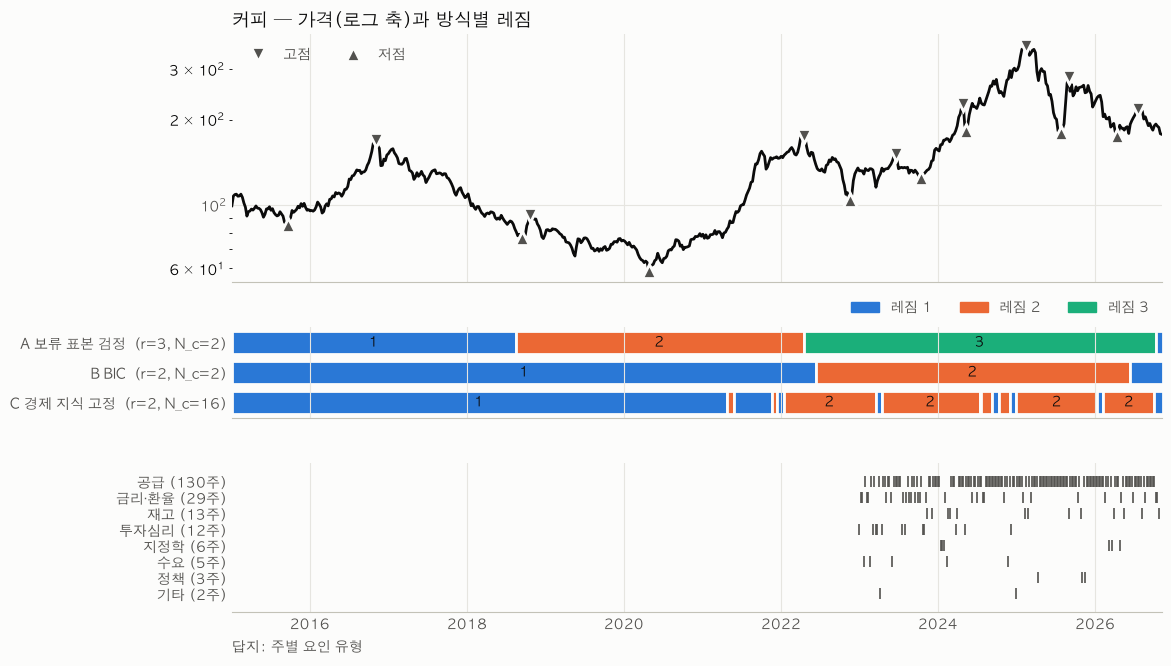

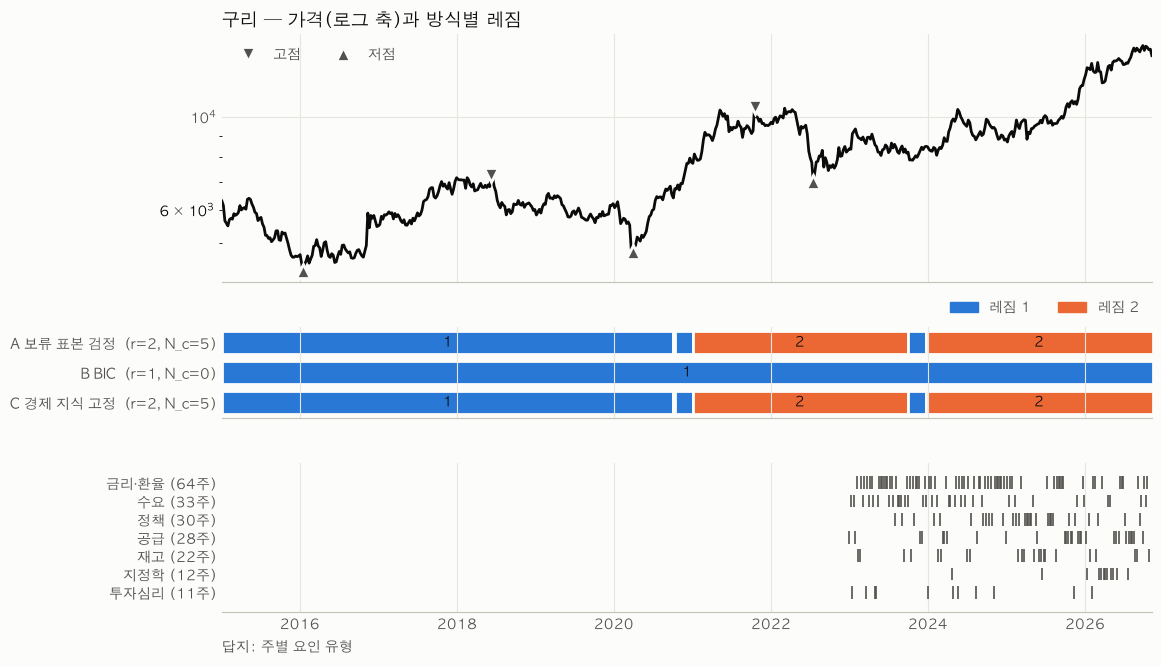

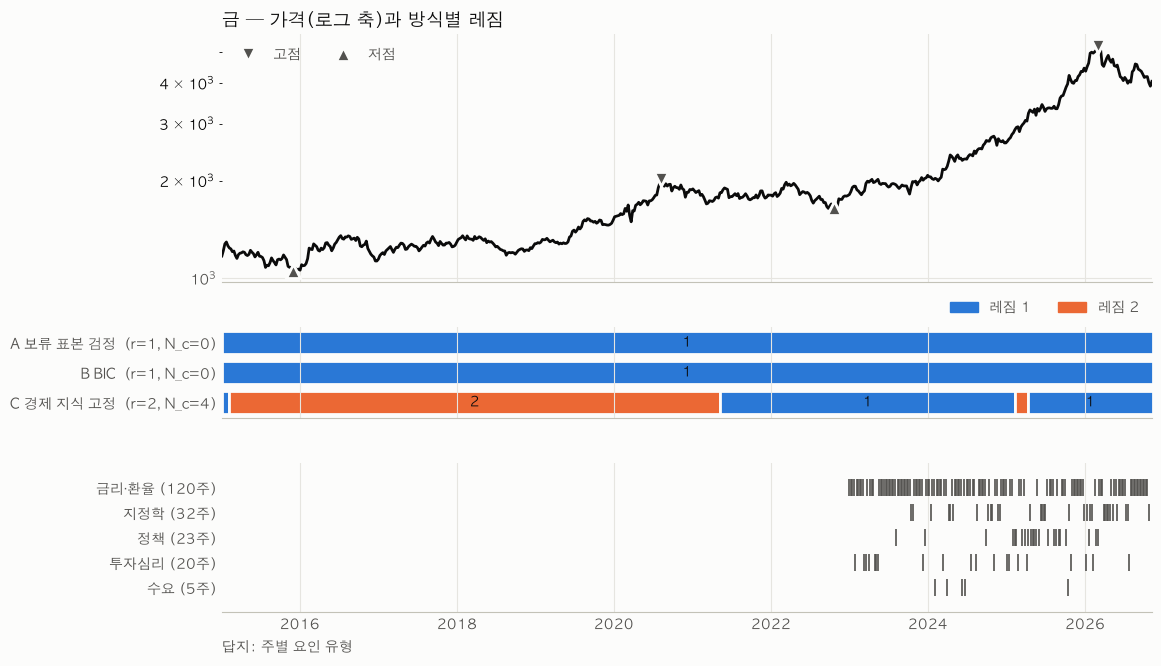

In [9]:
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}  # 한글 글꼴: 설치된 첫 번째 것
plt.rcParams.update({"font.family": next((f for f in ("AppleGothic", "Malgun Gothic", "NanumGothic") if f in have), "sans-serif"),
                     "axes.unicode_minus": False})
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
REGIME = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # 레짐 번호(처음 등장한 순서)에 고정


def plot_regimes(s):
    X, methods = panels[s][0], [m for m in chosen[s] if m != "r=1 기준선"]
    logp, peaks, troughs = turning_points(s)
    types = keys[s].type.value_counts().index[::-1]
    fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, facecolor=SURFACE,
                                     gridspec_kw={"height_ratios": [3, 1.1, 1.8], "hspace": 0.28})
    a0.plot(logp.index, np.exp(logp), color=INK, lw=2)
    a0.plot(logp.index[peaks], np.exp(logp.values[peaks]), "v", ms=10, color=MUTED, mec=SURFACE, mew=2, ls="", label="고점")
    a0.plot(logp.index[troughs], np.exp(logp.values[troughs]), "^", ms=10, color=MUTED, mec=SURFACE, mew=2, ls="", label="저점")
    a0.set_yscale("log")
    a0.set_title(f"{SERIES[s]} — 가격(로그 축)과 방식별 레짐", loc="left", color=INK, fontsize=13)
    a0.legend(frameon=False, loc="upper left", ncol=2, labelcolor=MUTED)
    week = pd.Timedelta(weeks=1)
    for y, m in enumerate(methods):
        r, c = chosen[s][m]
        lab = fits[s, r, c]["full"]["labels"]
        edges = np.r_[0, np.flatnonzero(np.diff(lab)) + 1, len(lab)]
        for lo, hi in zip(edges[:-1], edges[1:]):
            a1.broken_barh([(X.index[lo], (hi - lo) * week)], (y - 0.38, 0.76), color=REGIME[lab[lo]], ec=SURFACE, lw=2)
            if hi - lo >= 26:  # 색만으로 구분하지 않도록 레짐 번호를 적는다
                a1.text(X.index[(lo + hi) // 2], y, str(lab[lo] + 1), ha="center", va="center", color=INK, fontsize=10)
    a1.set_yticks(range(len(methods)), [f"{m}  (r={chosen[s][m][0]}, N_c={chosen[s][m][1]})" for m in methods])
    a1.invert_yaxis()
    n_reg = max(chosen[s][m][0] for m in methods)
    a1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=REGIME[k]) for k in range(n_reg)],
              labels=[f"레짐 {k + 1}" for k in range(n_reg)], frameon=False, ncol=n_reg, loc="lower right",
              bbox_to_anchor=(1, 0.98), labelcolor=MUTED)
    a2.eventplot([keys[s].index[keys[s].type == t] for t in types], colors=MUTED, linelengths=0.7, linewidths=1.2)
    a2.set_yticks(range(len(types)), [f"{t} ({(keys[s].type == t).sum()}주)" for t in types])
    a2.set_xlabel("답지: 주별 요인 유형", color=MUTED, loc="left")
    for ax in (a0, a1, a2):
        ax.set_facecolor(SURFACE)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED, length=0)
        ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    a0.grid(axis="y", color="#e6e5e0", lw=0.8)
    a0.set_xlim(X.index[0], X.index[-1])
    plt.show()


for s in SERIES:
    plot_regimes(s)

## 8. 레짐별 가격의 Markov blanket

방식 A·B·C 가 고른 후보마다(같은 후보는 한 번만), 레짐별로 가격과 직접 이어진 변수를 적는다.
시차는 가격 시점 기준(−2 = 2주 전 값, +1 = 1주 뒤 값). 강도는 PCMCI+ 의 편상관. `답지 인용` 은 그 레짐의 답지 주들에서 그 변수가 원인으로 인용된 횟수다.

In [10]:
def blanket_table(s, r, c):
    X, f = panels[s][0], fits[s, r, c]["full"]
    cols = list(X.columns)
    lab = pd.Series(f["labels"], index=X.index)
    rows = []
    for k, ((A, val), mb) in enumerate(zip(f["graphs"], f["mbs"])):
        weeks = lab.index[lab == k]
        cites = keys[s].cited.reindex(weeks).dropna().explode().value_counts()
        for i, o in mb[0]:
            if o <= 0 and A[i, 0, -o]:
                kind, strength = "부모 → 가격", val[i, 0, -o]
            elif o >= 0 and A[0, i, o]:
                kind, strength = "가격 → 자식", val[0, i, o]
            else:
                kind, strength = "배우자 (자식의 다른 부모)", np.nan
            rows.append((f"레짐 {k + 1}", f"{weeks[0].date()} ~ {weeks[-1].date()} 중 {len(weeks)}주", cols[i][:60], o, kind,
                         strength, int(cites.get(cols[i], 0))))
    return pd.DataFrame(rows, columns=["레짐", "기간", "변수", "시차(주)", "관계", "강도", "답지 인용"]).round(3)


for s in SERIES:
    for r, c in sorted(set(chosen[s].values())):
        print(f"\n===== {SERIES[s]}  r={r}, N_c={c}  ({', '.join(m for m, v in chosen[s].items() if v == (r, c))})")
        print(blanket_table(s, r, c).to_string(index=False))


===== 커피  r=1, N_c=0  (r=1 기준선)
  레짐                             기간                                                           변수  시차(주)              관계     강도  답지 인용
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                                        price     -1         부모 → 가격  0.151      0
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                                        price      1         가격 → 자식  0.151      0
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                        Climate_USDM_CONUS_D0_D4_Area_Percent      1 배우자 (자식의 다른 부모)    NaN      0
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                           Com_CBOE_VIX_Index      0         부모 → 가격 -0.108      2
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                           Com_CBOE_VIX_Index      1 배우자 (자식의 다른 부모)    NaN      2
레짐 1 2015-01-04 ~ 2026-11-08 중 619주 Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F     -3 배우자 (자식의 다른 부모)    NaN      0
레짐 1 2015-01-04 ~ 2026-11-08 

## 9. 결과 요약과 한계

아래 숫자는 2026-11-08 까지의 스냅샷과 2026-11-13 에 고친 답지(`검토_변경` 시트 반영)로 돌린 결과다. 데이터나 답지를 바꾸면 6절의 표를 다시 읽는다.

| 원자재 | A 보류 표본 검정 | B BIC | C 경제 지식 고정 | 답지 원인 적중률 (r=1 기준선 → A / B / C) |
| --- | --- | --- | --- | --- |
| 커피 | r=3, N_c=2 | r=2, N_c=2 | r=2, N_c=16 | 0.55 → 0.31 / 0.09 / 0.36 |
| 구리 | r=2, N_c=5 | r=1 | r=2, N_c=5 | 0.39 → 0.49 / 0.39 / 0.49 |
| 금 | r=1 | r=1 | r=2, N_c=4 | 0.30 → 0.30 / 0.30 / 0.61 |

- 금은 데이터로 고르는 두 방식(A, B)이 모두 레짐을 나누지 않았다. 구리는 A 만, 커피는 A 와 B 가 레짐을 나눴다.
- 레짐을 나눈다고 답지 적중률이 일관되게 오르지 않는다. 커피는 레짐 없는 그래프가 가장 높고, 구리·금은 2레짐이 더 높다.
- 레짐과 답지 `요인 유형` 의 연관(Cramér V 0.13 ~ 0.26)은 어느 경우에도 p < 0.05 가 아니다. 답지가 말하는 "원인의 종류"와 이 방법이 찾은 레짐은 같은 것을 가리킨다고 볼 수 없다.

한계
- drivers 전부 + τ = 4 이면 N_ℓ = 9d 가 커서 구리·금은 레짐이 2개까지고, 두 레짐이 표본을 거의 반씩 나눠 가져야 한다(구리는 레짐당 270주 이상 / 전체 619주).
- 손실이 N_c 에 대해 단조가 아니다(구리 N_c = 2 가 N_c = 1 보다 손실이 크다). 초기화 20개로는 가장 좋은 해를 못 찾는 경우가 있다 — 한 번 배정된 주는 자기 레짐의 회귀에 들어가 그 레짐에 유리해지므로 초기 구간에 머무는 경향이 있다. `N_INIT` 를 늘리면 나아지지만 시간이 비례해 든다.
- 양 끝 4주는 시차 때문에 비용이 0 이라 배정이 임의다(그림 끝의 얇은 조각).
- 계단형 변수끼리의 검정은 유효 표본이 발표 횟수라 p 값이 낙관적이다.
- 방식 A 의 순차 검정은 다중 비교를 보정하지 않는다.
- 답지는 2023 이후만 있어 그 전 레짐은 채점되지 않는다.
- 고친 답지는 drivers 밖의 변수도 원인으로 든다(커피 인용 162건 중 61건 — 대부분 브라질 미나스 강수 `nasa_power_daily_minas_br_precip`, 구리 35/188, 금 23/195). 분석에 없는 변수만 인용된 주는 채점에서 빠진다.